## 1. Accès au dataset

Sur Colab, monter Google Drive et extraire `MyDrive/data.zip` dans
`/content/dataset` avec la cellule suivante. Pour une exécution locale,
remplacer cette cellule par `DATA_PATH = Path('../data/raw')` si le notebook
est lancé depuis `notebooks`, ou `DATA_PATH = Path('data/raw')` depuis le projet.

Les bibliothèques EDA sont NumPy, pandas, Matplotlib, Seaborn et OpenCV.
Si elles ne sont pas installées, exécuter dans une cellule :
`%pip install numpy pandas matplotlib seaborn opencv-python-headless`.

In [7]:
from pathlib import Path
import zipfile
from google.colab import drive

drive.mount('/content/drive')
ZIP_PATH = Path('/content/drive/MyDrive/data.zip')
DATA_PATH = Path('/content/dataset')
DATA_PATH.mkdir(parents=True, exist_ok=True)
if ZIP_PATH.is_file():
        with zipfile.ZipFile(ZIP_PATH) as archive:
            archive.extractall(DATA_PATH)

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [8]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

CLASSES = ['glioma', 'meningioma', 'notumor', 'pituitary']
EXTENSIONS = ['.jpg', '.jpeg', '.png', '.bmp', '.webp']
SEED = 42

## 2. Inventaire et qualité des fichiers avec OpenCV

Nous allons suivre quatre étapes simples : trouver les fichiers, identifier
leur classe, lire chaque image, puis enregistrer ses informations dans un tableau.
Une ligne du tableau correspond à une image lisible. Nous lisons une image à la
fois pour éviter de garder tout le dataset en mémoire.

`cv2.imread` lit les images en BGR (bleu, vert, rouge), avec trois canaux 8 bits.
`cv2.cvtColor` crée une vue en niveaux de gris pour calculer les intensités.
Les fichiers originaux ne sont pas modifiés. Les dimensions ne sont pas redimensionnées.

In [9]:
files = []
for path in DATA_PATH.rglob('*'):
    if path.is_file():
        files.append(path)
files.sort()

records = []
rejected = []

for path in files:
    extension = path.suffix.lower()
    if extension not in EXTENSIONS:
        rejected.append({'path': str(path), 'reason': 'format non pris en charge'})
        continue  

    
    label = None
    for folder in path.parents:
        if folder == DATA_PATH:
            break
        folder_name = folder.name.lower()
        if folder_name in CLASSES:
            label = folder_name
            break  

    if label is None:
        rejected.append({'path': str(path), 'reason': 'classe inconnue'})
        continue

    try:
        image = cv2.imread(str(path))
        if image is None:
            rejected.append({'path': str(path), 'reason': 'image illisible'})
            continue

        height = image.shape[0]
        width = image.shape[1]
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

        information = {
            'path': str(path),
            'label': label,
            'extension': extension,
            'width': width,
            'height': height,
            'aspect_ratio': width / height,
            'size_kb': path.stat().st_size / 1024,
            'mean_intensity': gray.mean(),
            'std_intensity': gray.std(),
            'black_fraction': np.count_nonzero(gray == 0) / gray.size,
        }
        records.append(information)

    except (OSError, cv2.error) as error:
        rejected.append({'path': str(path), 'reason': str(error)})

eda_df = pd.DataFrame(records)
rejected_df = pd.DataFrame(rejected, columns=['path', 'reason'])

print('Fichiers examinés :', len(files))
print('Images lisibles :', len(records))
print('Fichiers écartés :', len(rejected))

if eda_df.empty:
    raise ValueError('Aucune image lisible : vérifier DATA_PATH et les dossiers de classe.')

display(eda_df.head())
display(eda_df['extension'].value_counts())

if len(rejected) > 0:
    display(rejected_df.head(10))

Fichiers examinés : 7023
Images lisibles : 7023
Fichiers écartés : 0


,path,label,extension,width,height,aspect_ratio,size_kb,mean_intensity,std_intensity,black_fraction
0,/content/dataset/Data/glioma/Te-glTr_0000.jpg,glioma,.jpg,512,512,1.0,25.220703,30.513634,39.602723,0.323242
1,/content/dataset/Data/glioma/Te-glTr_0001.jpg,glioma,.jpg,512,512,1.0,20.490234,23.499611,31.120606,0.317268
2,/content/dataset/Data/glioma/Te-glTr_0002.jpg,glioma,.jpg,512,512,1.0,12.973633,17.359077,25.487901,0.330914
3,/content/dataset/Data/glioma/Te-glTr_0003.jpg,glioma,.jpg,512,512,1.0,25.524414,31.820053,44.951605,0.279606
4,/content/dataset/Data/glioma/Te-glTr_0004.jpg,glioma,.jpg,512,512,1.0,21.200195,25.002510,32.717615,0.295399


,count
extension,
.jpg,7023


## 3. Répartition et équilibre des classes

Les effectifs et pourcentages portent sur les images lisibles, avant toute
suppression de doublons. Le rapport classe la plus fréquente / classe la moins
fréquente indique le degré de déséquilibre (1 signifie des effectifs égaux).
Une classe absente est affichée avec un effectif nul.

,images,pourcentage
label,,
glioma,1621,23.08
meningioma,1645,23.42
notumor,2000,28.48
pituitary,1757,25.02


Rapport max/min : 1.23


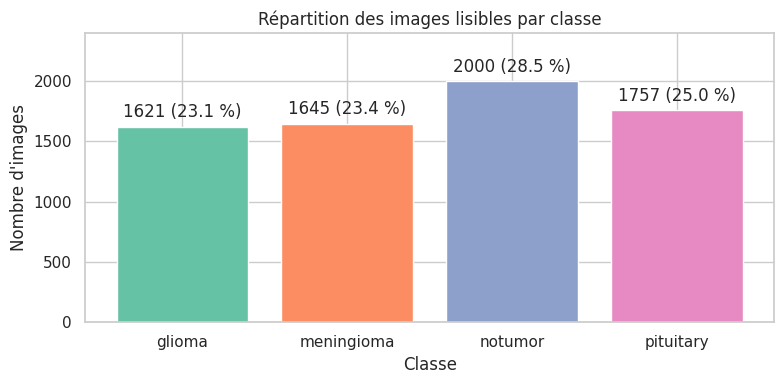

In [10]:
class_counts = eda_df['label'].value_counts().reindex(CLASSES, fill_value=0)
class_summary = class_counts.rename('images').to_frame()
class_summary['pourcentage'] = (100 * class_counts / len(eda_df)).round(2)
display(class_summary)
missing_classes = class_counts.index[class_counts.eq(0)].tolist()
imbalance_ratio = (float(class_counts.max() / class_counts.min())
                   if not missing_classes else float('inf'))
print(f'Rapport max/min : {imbalance_ratio:.2f}')
if missing_classes:
    print(f'Classes absentes : {missing_classes}')

fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(CLASSES, class_counts.to_numpy(), color=sns.color_palette('Set2', 4))
ax.bar_label(bars, labels=[f'{n} ({p:.1f} %)' for n, p in
                         zip(class_counts, class_summary['pourcentage'])], padding=4)
ax.set(title='Répartition des images lisibles par classe', xlabel='Classe', ylabel="Nombre d'images")
ax.set_ylim(0, class_counts.max() * 1.2)
plt.tight_layout()
plt.show()

## 4. Échantillons visuels par classe

Trois images distinctes sont tirées par classe avec une graine fixe pour rendre
la sélection reproductible. Les dimensions affichées sont celles des images
originales. Observer les orientations, le cadrage, les bordures, les annotations
et le contraste ; cette inspection ne permet pas de valider les diagnostics.

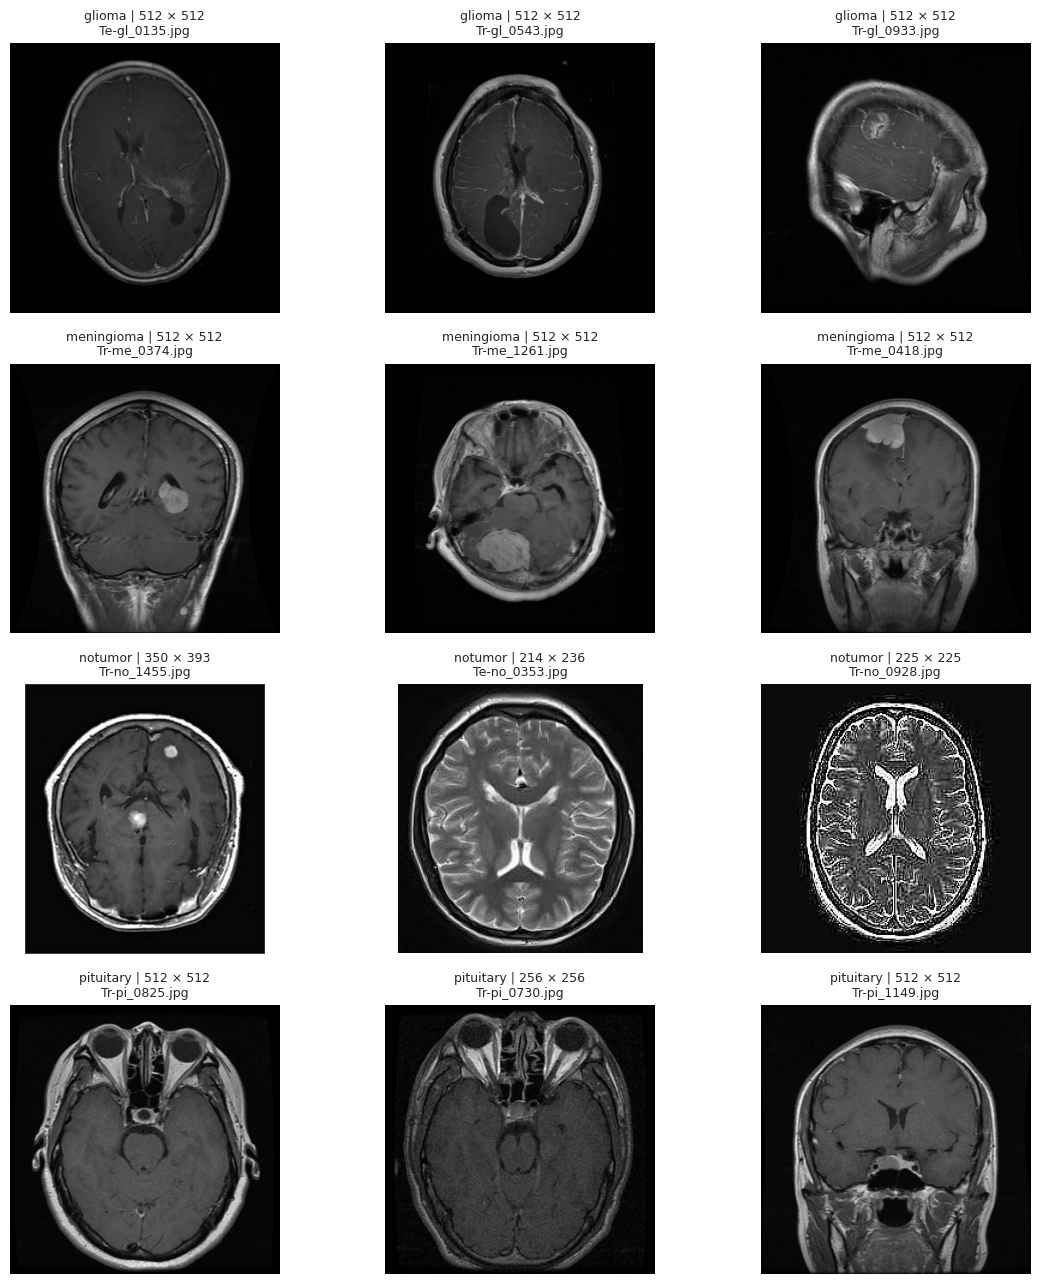

In [ ]:
SAMPLES_PER_CLASS = 3
fig, axes = plt.subplots(len(CLASSES), SAMPLES_PER_CLASS, figsize=(12, 13), squeeze=False)
for row, label in enumerate(CLASSES):
    subset = eda_df.loc[eda_df['label'].eq(label)]
    samples = subset.sample(n=min(SAMPLES_PER_CLASS, len(subset)), random_state=SEED)
    for col, ax in enumerate(axes[row]):
        ax.axis('off')
        if col >= len(samples):
            ax.set_title(f'{label} — aucun autre exemple')
            continue
        record = samples.iloc[col]
        image = cv2.imread(record['path'])
        image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        ax.imshow(image_rgb)
        ax.set_title(f"{label} | {record['width']} × {record['height']}\n{Path(record['path']).name}", fontsize=9)
plt.tight_layout()
plt.show()

## 5. Dimensions et formats

Examiner les tailles et les rapports largeur/hauteur avant de choisir un futur
redimensionnement. Un ratio éloigné de 1 implique qu'un passage direct à un carré
peut déformer l'image. Les graphiques présentent uniquement les dimensions originales.

,width,height,aspect_ratio,size_kb
count,7023.00,7023.00,7023.00,7023.00
mean,445.89,448.35,0.99,22.05
std,132.33,126.28,0.11,15.83
min,150.00,168.00,0.64,3.39
25%,393.00,403.50,1.00,14.99
50%,512.00,512.00,1.00,20.56
75%,512.00,512.00,1.00,26.39
max,1920.00,1446.00,1.79,710.85


,,images
width,height,
512,512,4742
225,225,332
630,630,90
236,236,81
201,251,58
228,221,51
232,217,50
300,168,49
442,442,46


,width,height,aspect_ratio
label,,,
glioma,512.0,512.0,1.0
meningioma,512.0,512.0,1.0
notumor,232.0,243.0,1.0
pituitary,512.0,512.0,1.0


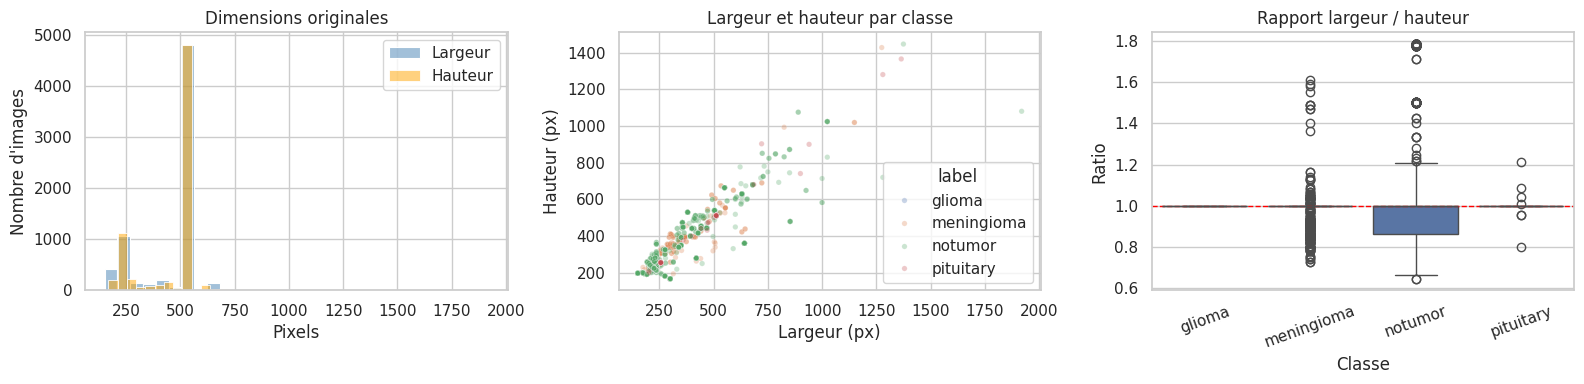

In [12]:
display(eda_df[['width', 'height', 'aspect_ratio', 'size_kb']].describe().round(2))
display(eda_df.groupby(['width', 'height']).size().sort_values(ascending=False)
        .head(10).rename('images').to_frame())
display(eda_df.groupby('label')[['width', 'height', 'aspect_ratio']]
        .median().reindex(CLASSES).round(2))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
sns.histplot(data=eda_df, x='width', bins=30, ax=axes[0], color='steelblue', label='Largeur', alpha=0.5)
sns.histplot(data=eda_df, x='height', bins=30, ax=axes[0], color='orange', label='Hauteur', alpha=0.5)
axes[0].set(title='Dimensions originales', xlabel='Pixels', ylabel="Nombre d'images")
axes[0].legend()
sns.scatterplot(data=eda_df, x='width', y='height', hue='label', hue_order=CLASSES,
                alpha=0.3, s=15, ax=axes[1])
axes[1].set(title='Largeur et hauteur par classe', xlabel='Largeur (px)', ylabel='Hauteur (px)')
sns.boxplot(data=eda_df, x='label', y='aspect_ratio', order=CLASSES, ax=axes[2])
axes[2].axhline(1, color='red', linestyle='--', linewidth=1)
axes[2].set(title='Rapport largeur / hauteur', xlabel='Classe', ylabel='Ratio')
axes[2].tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()

## 6. Intensité et contraste

La moyenne et l'écart-type des pixels sont mesurés sur une vue en niveaux de gris
8 bits (0 à 255). L'écart-type décrit la dispersion des intensités, sans mesurer
à lui seul la qualité clinique. La fraction de pixels noirs peut refléter les
bordures ou l'arrière-plan. Ces valeurs ne sont pas une normalisation des données
et ne représentent pas les intensités physiques d'une acquisition IRM.

mean_intensity         std_intensity         black_fraction       
                     mean  median          mean  median           mean median
label                                                                        
glioma             32.951  31.856        38.461  38.586          0.208  0.231
meningioma         45.149  41.317        47.603  45.800          0.140  0.164
notumor            60.390  56.833        60.276  58.300          0.182  0.103
pituitary          48.969  49.464        41.400  41.377          0.082  0.031

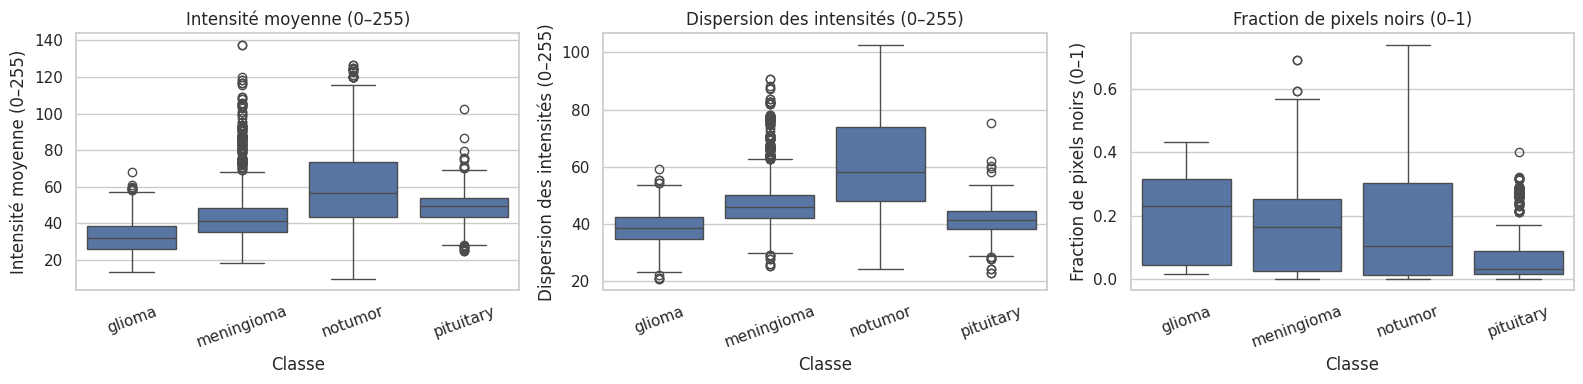

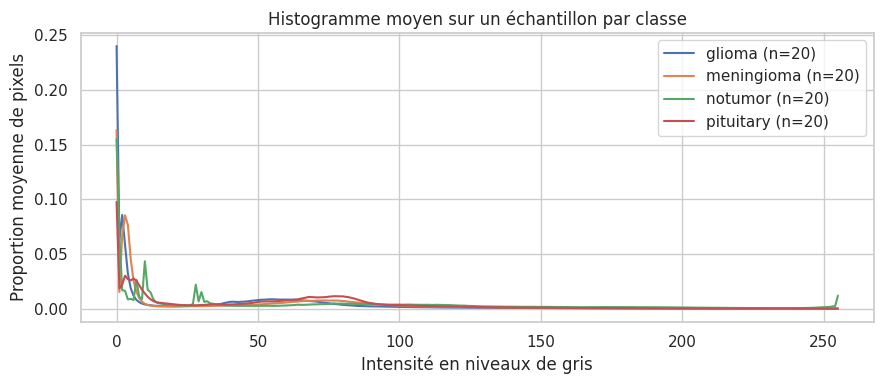

In [ ]:
display(eda_df.groupby('label')[['mean_intensity', 'std_intensity', 'black_fraction']]
        .agg(['mean', 'median']).reindex(CLASSES).round(3))
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, metric, title in zip(axes,
        ['mean_intensity', 'std_intensity', 'black_fraction'],
        ['Intensité moyenne (0–255)', 'Dispersion des intensités (0–255)', 'Fraction de pixels noirs (0–1)']):
    sns.boxplot(data=eda_df, x='label', y=metric, order=CLASSES, ax=ax)
    ax.set(title=title, xlabel='Classe', ylabel=title)
    ax.tick_params(axis='x', rotation=20)
plt.tight_layout()
plt.show()

fig, ax = plt.subplots(figsize=(9, 4))
for label in CLASSES:
    subset = eda_df.loc[eda_df['label'].eq(label)]
    samples = subset.sample(n=min(20, len(subset)), random_state=SEED)
    if samples.empty:
        continue
    histograms = []
    for image_path in samples['path']:
        image = cv2.imread(image_path)
        gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)
        hist = np.bincount(gray.ravel(), minlength=256).astype(float)
        histograms.append(hist / hist.sum())
    ax.plot(np.arange(256), np.mean(histograms, axis=0), label=f'{label} (n={len(samples)})')
ax.set(title='Histogramme moyen sur un échantillon par classe',
       xlabel='Intensité en niveaux de gris', ylabel='Proportion moyenne de pixels')
ax.legend()
plt.tight_layout()
plt.show()

In [ ]:
import hashlib

image_signatures = []
for image_path in eda_df['path']:
    image = cv2.imread(image_path)
    signature = hashlib.sha256()
    signature.update(str(image.shape).encode())
    signature.update(image.tobytes())
    image_signatures.append(signature.hexdigest())

eda_df['pixel_hash'] = image_signatures

duplicate_mask = eda_df.duplicated('pixel_hash', keep=False)
duplicates_df = eda_df.loc[duplicate_mask].copy()
duplicate_groups = duplicates_df['pixel_hash'].nunique()
duplicate_excess = len(eda_df) - eda_df['pixel_hash'].nunique()
conflict_hashes = eda_df.groupby('pixel_hash')['label'].nunique()
conflict_hashes = conflict_hashes.index[conflict_hashes.gt(1)]
conflicts_df = eda_df.loc[eda_df['pixel_hash'].isin(conflict_hashes)]
print(f'Groupes de doublons exacts : {duplicate_groups}')
print(f'Images dans ces groupes : {len(duplicates_df)} | Copies au-delà de la première : {duplicate_excess}')
print(f'Groupes présents sous plusieurs labels : {len(conflict_hashes)}')
if not duplicates_df.empty:
    display(duplicates_df.sort_values('pixel_hash')[['pixel_hash', 'label', 'path']].head(12))
if not conflicts_df.empty:
    display(conflicts_df[['pixel_hash', 'label', 'path']].sort_values('pixel_hash').head(12))

constant_images = eda_df.loc[eda_df['std_intensity'].eq(0)]
print(f'Images à intensité constante : {len(constant_images)}')
if not constant_images.empty:
    display(constant_images[['path', 'label', 'mean_intensity']].head(10))
print('Exemples aux dimensions extrêmes (à inspecter, pas à supprimer automatiquement) :')
display(pd.concat([eda_df.nsmallest(3, 'width'), eda_df.nlargest(3, 'width')])
        .drop_duplicates('path')[['label', 'path', 'width', 'height', 'aspect_ratio']])

Groupes de doublons exacts : 300
Images dans ces groupes : 726 | Copies au-delà de la première : 426
Groupes présents sous plusieurs labels : 0


,pixel_hash,label,path
2204,00f583953d36298bccb31075783211f1967f91e5dbd1a6...,meningioma,/content/dataset/Data/meningioma/Tr-me_0277.jpg
1721,00f583953d36298bccb31075783211f1967f91e5dbd1a6...,meningioma,/content/dataset/Data/meningioma/Te-me_0100.jpg
5673,024175eea25f7f59cc77c2fd269ad95979e4f6d37893ce...,pituitary,/content/dataset/Data/pituitary/Tr-pi_0107.jpg
5674,024175eea25f7f59cc77c2fd269ad95979e4f6d37893ce...,pituitary,/content/dataset/Data/pituitary/Tr-pi_0108.jpg
4037,02661f67a95daf748a1dc570b5394076c97d38e025e670...,notumor,/content/dataset/Data/notumor/Tr-no_0366.jpg
3788,02661f67a95daf748a1dc570b5394076c97d38e025e670...,notumor,/content/dataset/Data/notumor/Tr-no_0117.jpg
4766,02661f67a95daf748a1dc570b5394076c97d38e025e670...,notumor,/content/dataset/Data/notumor/Tr-no_1095.jpg
4040,02661f67a95daf748a1dc570b5394076c97d38e025e670...,notumor,/content/dataset/Data/notumor/Tr-no_0369.jpg
3802,02661f67a95daf748a1dc570b5394076c97d38e025e670...,notumor,/content/dataset/Data/notumor/Tr-no_0131.jpg
3752,030a2c9da814851834b264c54250499cf77f93cdb24dbe...,notumor,/content/dataset/Data/notumor/Tr-no_0081.jpg


Images à intensité constante : 0
Exemples aux dimensions extrêmes (à inspecter, pas à supprimer automatiquement) :


,label,path,width,height,aspect_ratio
3423,notumor,/content/dataset/Data/notumor/Te-no_0157.jpg,150,198,0.757576
3428,notumor,/content/dataset/Data/notumor/Te-no_0162.jpg,150,198,0.757576
3475,notumor,/content/dataset/Data/notumor/Te-no_0209.jpg,150,198,0.757576
4676,notumor,/content/dataset/Data/notumor/Tr-no_1005.jpg,1920,1080,1.777778
3809,notumor,/content/dataset/Data/notumor/Tr-no_0138.jpg,1375,1446,0.950899
5604,pituitary,/content/dataset/Data/pituitary/Tr-pi_0038.jpg,1365,1365,1.000000


## 8. Synthèse de l'EDA

La synthèse ci-dessous utilise les mesures observées. Les éventuelles décisions
de préparation restent à réaliser dans une autre étape du projet.

In [15]:
print(f'Dataset analysé : {len(eda_df):,} images lisibles, {len(rejected_df)} fichiers écartés.')
for label in CLASSES:
    print(f"  {label} : {class_counts[label]} images ({class_summary.loc[label, 'pourcentage']:.2f} %)")
if missing_classes:
    print(f'Compléter les classes absentes avant une classification à quatre classes : {missing_classes}.')
elif imbalance_ratio == 1:
    print('Les effectifs des quatre classes sont égaux.')
else:
    print(f'Les effectifs diffèrent : rapport max/min = {imbalance_ratio:.2f}.')
    print("À l'étape de préparation, évaluer le besoin de pondération sur le futur ensemble d'entraînement.")
print(f"Dimensions : largeur {eda_df['width'].min()}–{eda_df['width'].max()} px ; "
      f"hauteur {eda_df['height'].min()}–{eda_df['height'].max()} px ; "
      f"{len(eda_df[['width', 'height']].drop_duplicates())} tailles distinctes.")
print('Lecture OpenCV : vue BGR à trois canaux ; les modes originaux ne sont pas analysés.')
print(f'Doublons : {duplicate_groups} groupes, dont {len(conflict_hashes)} sous plusieurs labels.')
print(f'Images constantes : {len(constant_images)}.')
print('Vérifier les doublons et les labels contradictoires avant un futur découpage.')
print("Aucun identifiant patient/étude n'est fourni par cet inventaire : l'indépendance des images n'est pas établie.")
print('Les statistiques de contraste et les exemples visuels servent à repérer une hétérogénéité à examiner.')

Dataset analysé : 7,023 images lisibles, 0 fichiers écartés.
  glioma : 1621 images (23.08 %)
  meningioma : 1645 images (23.42 %)
  notumor : 2000 images (28.48 %)
  pituitary : 1757 images (25.02 %)
Les effectifs diffèrent : rapport max/min = 1.23.
À l'étape de préparation, évaluer le besoin de pondération sur le futur ensemble d'entraînement.
Dimensions : largeur 150–1920 px ; hauteur 168–1446 px ; 387 tailles distinctes.
Lecture OpenCV : vue BGR à trois canaux ; les modes originaux ne sont pas analysés.
Doublons : 300 groupes, dont 0 sous plusieurs labels.
Images constantes : 0.
Vérifier les doublons et les labels contradictoires avant un futur découpage.
Aucun identifiant patient/étude n'est fourni par cet inventaire : l'indépendance des images n'est pas établie.
Les statistiques de contraste et les exemples visuels servent à repérer une hétérogénéité à examiner.
